# Stacking Ensemble for Cardiovascular Disease Prediction — GPU Enabled
### Explainable Artificial Intelligence for CVD Prediction — Q1 Paper

**Architecture:** XGBoost + LightGBM + CatBoost + Random Forest → Logistic Regression (meta-learner)  
**Dataset:** Heart_disease_clean.csv (68,653 records, 13 features after engineering)  
**GPU Support:** XGBoost (CUDA), LightGBM (GPU), CatBoost (GPU) — Random Forest runs on CPU (no GPU support)  

---
**Notebook Sections:**
1. Install & Import Libraries
2. Load & Preprocess Data
3. Feature Engineering
4. Train/Validation/Test Split
5. Train Base Learners (GPU)
6. Generate Out-of-Fold (OOF) Meta-Features
7. Train Meta-Learner (Stacking)
8. Evaluate Stacking Ensemble
9. Compare All Models
10. SHAP Explainability
11. SHAP Local Explanation
12. Confusion Matrix
13. ROC Curve
14. Summary Table

## 1. Install & Import Libraries

In [1]:
# Install required libraries (run once)
!pip install xgboost lightgbm catboost shap scikit-learn pandas numpy matplotlib seaborn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    precision_score, recall_score,
    confusion_matrix, classification_report,
    roc_curve, precision_recall_curve, average_precision_score
)

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

# ── GPU detection ─────────────────────────────────────────────
import subprocess
try:
    result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    GPU_AVAILABLE = result.returncode == 0
except:
    GPU_AVAILABLE = False

print(f'GPU available : {GPU_AVAILABLE}')
if GPU_AVAILABLE:
    print('XGBoost  → device=cuda')
    print('LightGBM → device=gpu')
    print('CatBoost → task_type=GPU')
    print('RandomForest → CPU (no GPU support in sklearn)')
else:
    print('Running on CPU for all models')

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print('\nAll libraries imported successfully!')
print(f'XGBoost version  : {xgb.__version__}')
print(f'LightGBM version : {lgb.__version__}')
print(f'Scikit-learn     : {__import__("sklearn").__version__}')

GPU available : True
XGBoost  → device=cuda
LightGBM → device=gpu
CatBoost → task_type=GPU
RandomForest → CPU (no GPU support in sklearn)

All libraries imported successfully!
XGBoost version  : 3.2.0
LightGBM version : 4.6.0
Scikit-learn     : 1.7.2


## 2. Load & Preprocess Data

In [3]:
# ── Load dataset ─────────────────────────────────────────────
df = pd.read_csv('Heart_disease_clean.csv')

print('Dataset shape:', df.shape)
print('\nColumns:')
for i, col in enumerate(df.columns):
    print(f'  [{i}] {col}')

print('\nTarget distribution:')
print(df['cardiovascular disease'].value_counts())
print('\nMissing values:', df.isnull().sum().sum())

Dataset shape: (68653, 11)

Columns:
  [0] Gender (0: female, 1: male)
  [1] age(years)
  [2] BMI
  [3] ap_hi(Systolic blood pressure)
  [4] ap_lo(Diastolic blood pressure)
  [5] cholesterol(1: normal, 2: above normal, 3: well above normal)
  [6] Glucose(1: normal, 2: above normal, 3: well above normal)
  [7] smoking
  [8] alcohol
  [9] active
  [10] cardiovascular disease

Target distribution:
cardiovascular disease
does not have cardiovascular disease    34706
has cardiovascular disease              33947
Name: count, dtype: int64

Missing values: 0


In [4]:
# ── Encode target ─────────────────────────────────────────────
df['target'] = (df['cardiovascular disease'] == 'has cardiovascular disease').astype(int)
df = df.drop(columns=['cardiovascular disease'])

print('Target encoded: 1 = CVD  |  0 = No CVD')
print(df['target'].value_counts())
print(f'Class balance: {df["target"].mean():.4f} positive (CVD)')

Target encoded: 1 = CVD  |  0 = No CVD
target
0    34706
1    33947
Name: count, dtype: int64
Class balance: 0.4945 positive (CVD)


In [5]:
# ── Additional data cleaning ──────────────────────────────────
df['PP_check'] = df['ap_hi(Systolic blood pressure)'] - df['ap_lo(Diastolic blood pressure)']

before = len(df)
df = df[
    df['BMI'].between(10, 60) &
    (df['PP_check'] > 0)
].reset_index(drop=True)
df = df.drop(columns=['PP_check'])

print(f'Rows before: {before}')
print(f'Rows after : {len(df)}')
print(f'Removed    : {before - len(df)} rows')

Rows before: 68653
Rows after : 68534
Removed    : 119 rows


## 3. Feature Engineering

In [6]:
# ── Engineer 3 haemodynamic features ─────────────────────────
df['PP'] = (
    df['ap_hi(Systolic blood pressure)'] -
    df['ap_lo(Diastolic blood pressure)']
)

df['MAP'] = (
    df['ap_hi(Systolic blood pressure)'] +
    2 * df['ap_lo(Diastolic blood pressure)']
) / 3

df['risk_count'] = (
    (df['cholesterol(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    (df['Glucose(1: normal, 2: above normal, 3: well above normal)'] > 1).astype(int) +
    df['smoking'] +
    df['alcohol'] +
    (1 - df['active'])
)

print('Engineered features added:')
print(f'  PP  (Pulse Pressure)    : min={df["PP"].min():.1f}  max={df["PP"].max():.1f}')
print(f'  MAP (Mean Art. Pressure): min={df["MAP"].min():.2f}  max={df["MAP"].max():.2f}')
print(f'  risk_count              : min={df["risk_count"].min()}  max={df["risk_count"].max()}')

Engineered features added:
  PP  (Pulse Pressure)    : min=5.0  max=135.0
  MAP (Mean Art. Pressure): min=53.33  max=153.33
  risk_count              : min=0  max=5


In [7]:
# ── Define feature set & short names ─────────────────────────
FEATURES = [
    'Gender (0: female, 1: male)',
    'age(years)',
    'BMI',
    'ap_hi(Systolic blood pressure)',
    'ap_lo(Diastolic blood pressure)',
    'cholesterol(1: normal, 2: above normal, 3: well above normal)',
    'Glucose(1: normal, 2: above normal, 3: well above normal)',
    'smoking',
    'alcohol',
    'active',
    'PP',
    'MAP',
    'risk_count'
]

FEAT_NAMES = [
    'Gender', 'Age', 'BMI', 'SBP', 'DBP',
    'Cholesterol', 'Glucose', 'Smoking', 'Alcohol',
    'Active', 'PP', 'MAP', 'RiskCount'
]

X = df[FEATURES].values
y = df['target'].values

print(f'Feature matrix X shape: {X.shape}')
print(f'Target vector  y shape: {y.shape}')
print(f'Number of features    : {len(FEATURES)}')

Feature matrix X shape: (68534, 13)
Target vector  y shape: (68534,)
Number of features    : 13


## 4. Train / Validation / Test Split (70 / 15 / 15)

In [8]:
# ── Stratified 70/15/15 split ─────────────────────────────────
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.15, random_state=RANDOM_STATE, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.1765, random_state=RANDOM_STATE, stratify=y_tmp
)

print(f'Training   set : {len(X_train):>6} records  ({len(X_train)/len(X)*100:.1f}%)')
print(f'Validation set : {len(X_val):>6} records  ({len(X_val)/len(X)*100:.1f}%)')
print(f'Test       set : {len(X_test):>6} records  ({len(X_test)/len(X)*100:.1f}%)')
print(f'\nClass balance in training: {y_train.mean():.4f} CVD positive')
print(f'Class balance in test    : {y_test.mean():.4f} CVD positive')

Training   set :  47971 records  (70.0%)
Validation set :  10282 records  (15.0%)
Test       set :  10281 records  (15.0%)

Class balance in training: 0.4944 CVD positive
Class balance in test    : 0.4944 CVD positive


In [9]:
# ── Scale features (used only by Random Forest) ───────────────
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_val_sc   = scaler.transform(X_val)
X_test_sc  = scaler.transform(X_test)

print('StandardScaler fitted on training data only (no data leakage)')

StandardScaler fitted on training data only (no data leakage)


## 5. Train Base Learners — GPU Accelerated

| Model | GPU param |
|---|---|
| XGBoost | `tree_method='hist', device='cuda'` |
| LightGBM | `device='gpu'` |
| CatBoost | `task_type='GPU'` |
| Random Forest | CPU only (`n_jobs=-1`) |

In [10]:
# ── Base Learner 1: XGBoost (GPU) ─────────────────────────────
print('Training Base Learner 1: XGBoost (GPU) ...')

xgb_model = xgb.XGBClassifier(
    n_estimators          = 500,
    max_depth             = 5,
    learning_rate         = 0.05,
    subsample             = 0.8,
    colsample_bytree      = 0.8,
    min_child_weight      = 3,
    gamma                 = 0.1,
    reg_alpha             = 0.1,
    reg_lambda            = 1.5,
    eval_metric           = 'auc',
    early_stopping_rounds = 30,
    random_state          = RANDOM_STATE,
    verbosity             = 0,
    # ── GPU params ──────────────────────────────────────────
    tree_method           = 'hist',          # required for GPU
    device                = 'cuda' if GPU_AVAILABLE else 'cpu'
)
xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

xgb_test_proba = xgb_model.predict_proba(X_test)[:, 1]
xgb_test_pred  = xgb_model.predict(X_test)
print(f'  XGBoost  AUC={roc_auc_score(y_test, xgb_test_proba):.4f}  '
      f'Acc={accuracy_score(y_test, xgb_test_pred):.4f}  '
      f'F1={f1_score(y_test, xgb_test_pred):.4f}  '
      f'Best iter={xgb_model.best_iteration}')

Training Base Learner 1: XGBoost (GPU) ...
  XGBoost  AUC=0.8002  Acc=0.7329  F1=0.7179  Best iter=185


In [11]:
# ── Base Learner 2: LightGBM (GPU) ────────────────────────────
print('Training Base Learner 2: LightGBM (GPU) ...')

lgb_model = lgb.LGBMClassifier(
    n_estimators      = 500,
    num_leaves        = 63,
    max_depth         = 6,
    learning_rate     = 0.05,
    subsample         = 0.8,
    colsample_bytree  = 0.8,
    min_child_samples = 20,
    reg_alpha         = 0.1,
    reg_lambda        = 1.0,
    random_state      = RANDOM_STATE,
    verbose           = -1,
    # ── GPU param ───────────────────────────────────────────
    device            = 'gpu' if GPU_AVAILABLE else 'cpu'
)
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    callbacks=[
        lgb.early_stopping(30, verbose=False),
        lgb.log_evaluation(-1)
    ]
)

lgb_test_proba = lgb_model.predict_proba(X_test)[:, 1]
lgb_test_pred  = lgb_model.predict(X_test)
print(f'  LightGBM AUC={roc_auc_score(y_test, lgb_test_proba):.4f}  '
      f'Acc={accuracy_score(y_test, lgb_test_pred):.4f}  '
      f'F1={f1_score(y_test, lgb_test_pred):.4f}  '
      f'Best iter={lgb_model.best_iteration_}')

Training Base Learner 2: LightGBM (GPU) ...
  LightGBM AUC=0.7995  Acc=0.7338  F1=0.7174  Best iter=102


In [12]:
# ── Base Learner 3: CatBoost (GPU) ────────────────────────────
print('Training Base Learner 3: CatBoost (GPU) ...')

cat_model = CatBoostClassifier(
    iterations            = 500,
    depth                 = 6,
    learning_rate         = 0.05,
    l2_leaf_reg           = 3,
    bagging_temperature   = 0.5,
    eval_metric           = 'AUC',
    early_stopping_rounds = 30,
    random_state          = RANDOM_STATE,
    verbose               = 0,
    # ── GPU param ───────────────────────────────────────────
    task_type             = 'GPU' if GPU_AVAILABLE else 'CPU'
)
cat_model.fit(
    X_train, y_train,
    eval_set=(X_val, y_val),
    verbose=False
)

cat_test_proba = cat_model.predict_proba(X_test)[:, 1]
cat_test_pred  = (cat_test_proba >= 0.5).astype(int)
print(f'  CatBoost AUC={roc_auc_score(y_test, cat_test_proba):.4f}  '
      f'Acc={accuracy_score(y_test, cat_test_pred):.4f}  '
      f'F1={f1_score(y_test, cat_test_pred):.4f}  '
      f'Best iter={cat_model.best_iteration_}')

Training Base Learner 3: CatBoost (GPU) ...


Default metric period is 5 because AUC is/are not implemented for GPU


  CatBoost AUC=0.8001  Acc=0.7329  F1=0.7164  Best iter=216


In [13]:
# ── Base Learner 4: Random Forest (CPU — no GPU support) ──────
print('Training Base Learner 4: Random Forest (CPU) ...')

rf_model = RandomForestClassifier(
    n_estimators     = 300,
    max_depth        = 10,
    min_samples_leaf = 5,
    max_features     = 'sqrt',
    random_state     = RANDOM_STATE,
    n_jobs           = -1   # use all CPU cores
)
rf_model.fit(X_train_sc, y_train)

rf_test_proba = rf_model.predict_proba(X_test_sc)[:, 1]
rf_test_pred  = rf_model.predict(X_test_sc)
print(f'  RandForest AUC={roc_auc_score(y_test, rf_test_proba):.4f}  '
      f'Acc={accuracy_score(y_test, rf_test_pred):.4f}  '
      f'F1={f1_score(y_test, rf_test_pred):.4f}')

Training Base Learner 4: Random Forest (CPU) ...
  RandForest AUC=0.7995  Acc=0.7322  F1=0.7112


## 6. Generate Out-of-Fold (OOF) Meta-Features

**Why OOF?** Training base learners on the full training set and using their training-set predictions as meta-features causes data leakage. OOF trains on *other* folds and predicts the *held-out* fold — the meta-learner never sees predictions from data used to train the base learners.

In [14]:
# ── 5-Fold OOF Predictions (GPU) ─────────────────────────────
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=RANDOM_STATE)

oof_xgb = np.zeros(len(X_train))
oof_lgb = np.zeros(len(X_train))
oof_cat = np.zeros(len(X_train))
oof_rf  = np.zeros(len(X_train))

print(f'Running {N_FOLDS}-fold OOF predictions (GPU accelerated)...')
print(f'Each fold: ~{len(X_train)//N_FOLDS:,} validation samples\n')

for fold, (tr_idx, vl_idx) in enumerate(skf.split(X_train, y_train)):
    print(f'--- Fold {fold + 1} / {N_FOLDS} ---')

    Xtr, Xvl       = X_train[tr_idx],    X_train[vl_idx]
    ytr, yvl       = y_train[tr_idx],    y_train[vl_idx]
    Xtr_sc, Xvl_sc = X_train_sc[tr_idx], X_train_sc[vl_idx]

    # ── XGBoost fold (GPU) ──────────────────────────────────
    m_xgb = xgb.XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        eval_metric='auc', random_state=RANDOM_STATE, verbosity=0,
        tree_method='hist',
        device='cuda' if GPU_AVAILABLE else 'cpu'
    )
    m_xgb.fit(Xtr, ytr, verbose=False)
    oof_xgb[vl_idx] = m_xgb.predict_proba(Xvl)[:, 1]

    # ── LightGBM fold (GPU) ─────────────────────────────────
    m_lgb = lgb.LGBMClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        random_state=RANDOM_STATE, verbose=-1,
        device='gpu' if GPU_AVAILABLE else 'cpu'
    )
    m_lgb.fit(Xtr, ytr)
    oof_lgb[vl_idx] = m_lgb.predict_proba(Xvl)[:, 1]

    # ── CatBoost fold (GPU) ─────────────────────────────────
    m_cat = CatBoostClassifier(
        iterations=300, depth=6, learning_rate=0.05,
        random_state=RANDOM_STATE, verbose=0,
        task_type='GPU' if GPU_AVAILABLE else 'CPU'
    )
    m_cat.fit(Xtr, ytr, verbose=False)
    oof_cat[vl_idx] = m_cat.predict_proba(Xvl)[:, 1]

    # ── Random Forest fold (CPU) ────────────────────────────
    m_rf = RandomForestClassifier(
        n_estimators=200, max_depth=10,
        min_samples_leaf=5,
        random_state=RANDOM_STATE, n_jobs=-1
    )
    m_rf.fit(Xtr_sc, ytr)
    oof_rf[vl_idx] = m_rf.predict_proba(Xvl_sc)[:, 1]

    print(f'  XGB={roc_auc_score(yvl, oof_xgb[vl_idx]):.4f}  '
          f'LGB={roc_auc_score(yvl, oof_lgb[vl_idx]):.4f}  '
          f'CAT={roc_auc_score(yvl, oof_cat[vl_idx]):.4f}  '
          f'RF={roc_auc_score(yvl, oof_rf[vl_idx]):.4f}')

print('\n=== OOF AUC (Cross-Validation) ===')
print(f'XGBoost      : {roc_auc_score(y_train, oof_xgb):.4f}')
print(f'LightGBM     : {roc_auc_score(y_train, oof_lgb):.4f}')
print(f'CatBoost     : {roc_auc_score(y_train, oof_cat):.4f}')
print(f'RandomForest : {roc_auc_score(y_train, oof_rf):.4f}')

Running 5-fold OOF predictions (GPU accelerated)...
Each fold: ~9,594 validation samples

--- Fold 1 / 5 ---
  XGB=0.8032  LGB=0.8024  CAT=0.8037  RF=0.8017
--- Fold 2 / 5 ---
  XGB=0.8038  LGB=0.8027  CAT=0.8055  RF=0.8033
--- Fold 3 / 5 ---
  XGB=0.8013  LGB=0.8010  CAT=0.8018  RF=0.8007
--- Fold 4 / 5 ---
  XGB=0.7950  LGB=0.7939  CAT=0.7953  RF=0.7938
--- Fold 5 / 5 ---
  XGB=0.7971  LGB=0.7956  CAT=0.7980  RF=0.7965

=== OOF AUC (Cross-Validation) ===
XGBoost      : 0.8000
LightGBM     : 0.7991
CatBoost     : 0.8008
RandomForest : 0.7991


In [15]:
# ── Build meta-feature matrices ───────────────────────────────
meta_X_train = np.column_stack([oof_xgb, oof_lgb, oof_cat, oof_rf])

meta_X_test = np.column_stack([
    xgb_model.predict_proba(X_test)[:, 1],
    lgb_model.predict_proba(X_test)[:, 1],
    cat_model.predict_proba(X_test)[:, 1],
    rf_model.predict_proba(X_test_sc)[:, 1]
])

print('Meta-feature matrix shapes:')
print(f'  meta_X_train : {meta_X_train.shape}  (OOF predictions)')
print(f'  meta_X_test  : {meta_X_test.shape}   (test predictions)')
print('\nMeta-feature columns: [XGB_prob, LGB_prob, CAT_prob, RF_prob]')

Meta-feature matrix shapes:
  meta_X_train : (47971, 4)  (OOF predictions)
  meta_X_test  : (10281, 4)   (test predictions)

Meta-feature columns: [XGB_prob, LGB_prob, CAT_prob, RF_prob]


## 7. Train Meta-Learner (Stacking)

In [16]:
# ── Meta-learner: Logistic Regression ────────────────────────
meta_learner = LogisticRegression(
    C=1.0, max_iter=1000, random_state=RANDOM_STATE
)
meta_learner.fit(meta_X_train, y_train)

print('Meta-learner trained on OOF predictions.')
print('\nMeta-learner coefficients (learnt weights per base model):')
coef = meta_learner.coef_[0]
for name, w in zip(['XGBoost','LightGBM','CatBoost','RandomForest'], coef):
    bar = '█' * int(abs(w) / max(abs(coef)) * 20)
    print(f'  {name:12s}  weight = {w:.4f}  {bar}')

Meta-learner trained on OOF predictions.

Meta-learner coefficients (learnt weights per base model):
  XGBoost       weight = 1.2480  ███████
  LightGBM      weight = -0.3389  ██
  CatBoost      weight = 3.1310  ████████████████████
  RandomForest  weight = 0.7435  ████


## 8. Evaluate Stacking Ensemble

In [17]:
# ── Stacking Ensemble predictions ────────────────────────────
stack_proba = meta_learner.predict_proba(meta_X_test)[:, 1]
stack_pred  = (stack_proba >= 0.5).astype(int)

print('=' * 50)
print('   STACKING ENSEMBLE — TEST SET RESULTS')
print('=' * 50)
print(f'  ROC-AUC            : {roc_auc_score(y_test, stack_proba):.4f}')
print(f'  Accuracy           : {accuracy_score(y_test, stack_pred):.4f}  ({accuracy_score(y_test, stack_pred)*100:.2f}%)')
print(f'  F1-Score           : {f1_score(y_test, stack_pred):.4f}')
print(f'  Precision          : {precision_score(y_test, stack_pred):.4f}')
print(f'  Recall             : {recall_score(y_test, stack_pred):.4f}')
print(f'  Avg Precision (AP) : {average_precision_score(y_test, stack_proba):.4f}')
print('=' * 50)

   STACKING ENSEMBLE — TEST SET RESULTS
  ROC-AUC            : 0.8005
  Accuracy           : 0.7335  (73.35%)
  F1-Score           : 0.7171
  Precision          : 0.7546
  Recall             : 0.6831
  Avg Precision (AP) : 0.7801


## 9. Compare All Models

                      AUC  Accuracy      F1  Precision  Recall
Model                                                         
Stacking Ensemble  0.8005    0.7335  0.7171     0.7546  0.6831
XGBoost            0.8002    0.7329  0.7179     0.7512  0.6874
CatBoost           0.8001    0.7329  0.7164     0.7540  0.6825
Random Forest      0.7995    0.7322  0.7112     0.7618  0.6669
LightGBM           0.7995    0.7338  0.7174     0.7549  0.6835
MLP (baseline)     0.7970    0.7330  0.7180     0.7500  0.6760


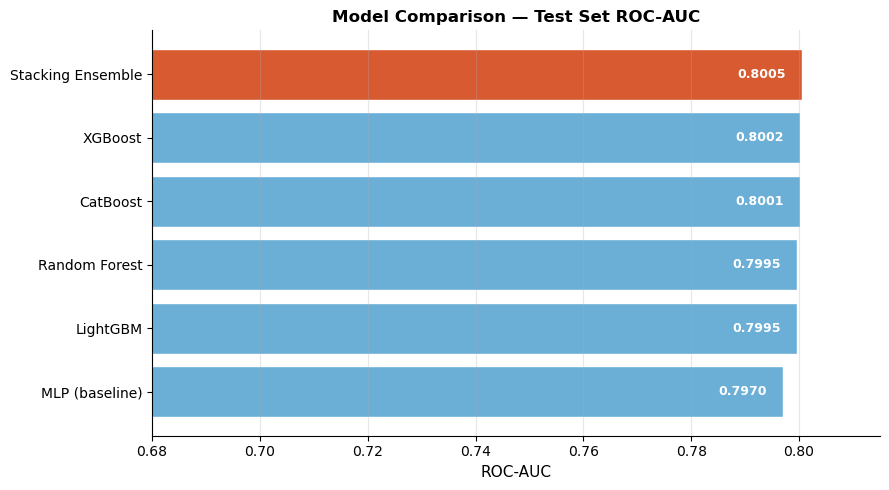

Figure saved: model_comparison.png


In [18]:
# ── Build comparison table ────────────────────────────────────
model_results = {
    'Stacking Ensemble' : (stack_proba,      stack_pred),
    'CatBoost'          : (cat_test_proba,   cat_test_pred),
    'XGBoost'           : (xgb_test_proba,   xgb_test_pred),
    'LightGBM'          : (lgb_test_proba,   lgb_test_pred),
    'Random Forest'     : (rf_test_proba,    rf_test_pred),
    'MLP (baseline)'    : (None, None),  # fill in manually if available
}

rows = []
for name, (proba, pred) in model_results.items():
    if proba is None:
        rows.append({'Model': name, 'AUC': 0.797, 'Accuracy': 0.733,
                     'F1': 0.718, 'Precision': 0.750, 'Recall': 0.676})
    else:
        rows.append({
            'Model'    : name,
            'AUC'      : roc_auc_score(y_test, proba),
            'Accuracy' : accuracy_score(y_test, pred),
            'F1'       : f1_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall'   : recall_score(y_test, pred)
        })

results_df = pd.DataFrame(rows).set_index('Model').sort_values('AUC', ascending=False)

print(results_df.round(4).to_string())

# ── Bar chart ─────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5))
colors  = ['#D85A30' if i == 0 else '#6BAED6' for i in range(len(results_df))]
bars = ax.barh(results_df.index[::-1], results_df['AUC'][::-1], color=colors[::-1], edgecolor='white')
for bar, val in zip(bars, results_df['AUC'][::-1]):
    ax.text(bar.get_width() - 0.003, bar.get_y() + bar.get_height()/2,
            f'{val:.4f}', va='center', ha='right', color='white', fontsize=9, fontweight='bold')
ax.set_xlabel('ROC-AUC', fontsize=11)
ax.set_title('Model Comparison — Test Set ROC-AUC', fontsize=12, fontweight='bold')
ax.set_xlim([0.68, 0.815])
ax.grid(axis='x', alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Figure saved: model_comparison.png')

## 10. SHAP Explainability (XGBoost)

Computing SHAP values...


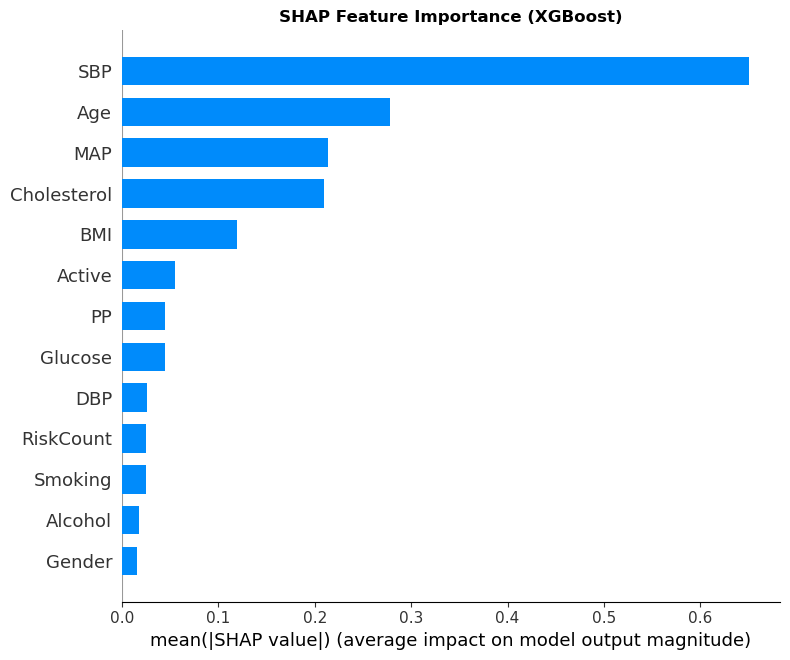

Saved: shap_bar_plot.png


In [19]:
# ── SHAP values for XGBoost ───────────────────────────────────
print('Computing SHAP values...')
explainer   = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Rename features for plots
import pandas as pd
X_test_df = pd.DataFrame(X_test, columns=FEAT_NAMES)

# ── SHAP bar plot ─────────────────────────────────────────────
plt.figure(figsize=(8, 5))
shap.summary_plot(shap_values, X_test_df, plot_type='bar', show=False)
plt.title('SHAP Feature Importance (XGBoost)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_bar_plot.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_bar_plot.png')

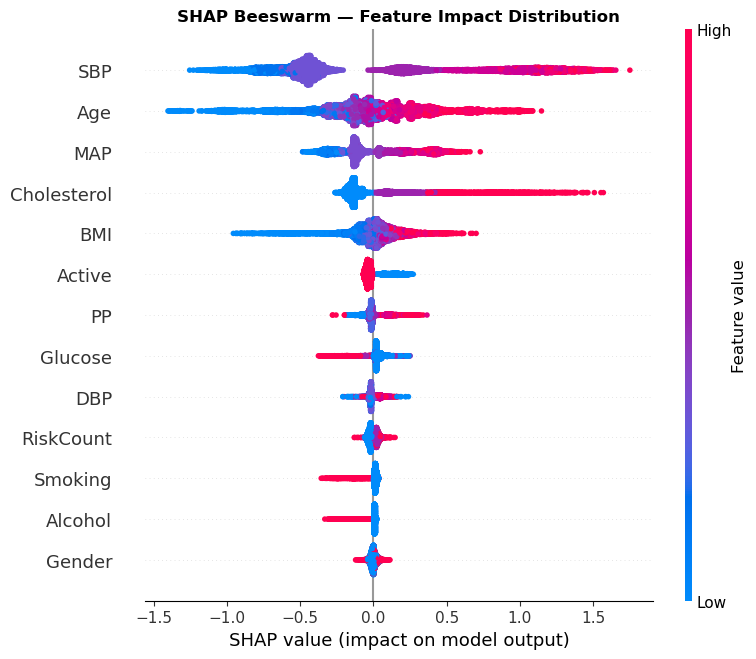

Saved: shap_beeswarm.png


In [20]:
# ── SHAP beeswarm plot ────────────────────────────────────────
plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_test_df, show=False)
plt.title('SHAP Beeswarm — Feature Impact Distribution', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_beeswarm.png')

<Figure size 700x500 with 0 Axes>

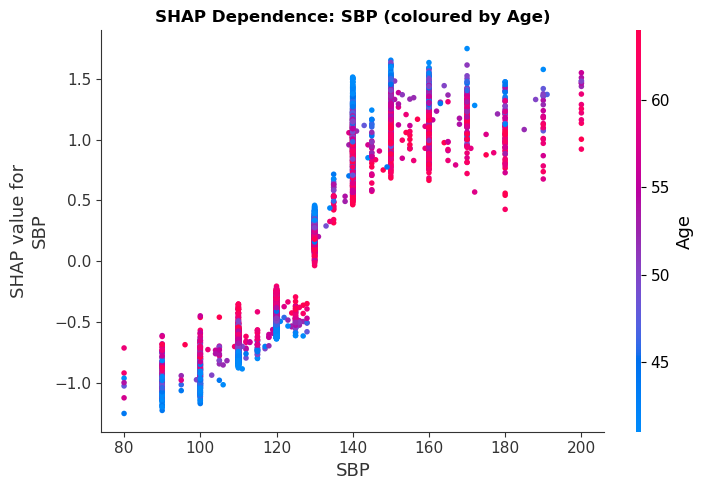

Saved: shap_dependence.png

SHAP Feature Ranking (XGBoost):
Rank  Feature         Mean |SHAP|
---------------------------------
1     SBP                  0.6501
2     Age                  0.2779
3     MAP                  0.2141
4     Cholesterol          0.2095
5     BMI                  0.1196
6     Active               0.0553
7     PP                   0.0451
8     Glucose              0.0449
9     DBP                  0.0258
10    RiskCount            0.0253
11    Smoking              0.0247
12    Alcohol              0.0174
13    Gender               0.0155


In [21]:



# ── SHAP dependence plot: SBP coloured by Age ─────────────────
sbp_idx = FEAT_NAMES.index('SBP')
age_idx = FEAT_NAMES.index('Age')

plt.figure(figsize=(7, 5))
shap.dependence_plot(sbp_idx, shap_values, X_test_df,
                     interaction_index=age_idx, show=False)
plt.title('SHAP Dependence: SBP (coloured by Age)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_dependence.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_dependence.png')

# Print ranked feature importances
mean_shap = np.abs(shap_values).mean(axis=0)
shap_rank = sorted(zip(FEAT_NAMES, mean_shap), key=lambda x: x[1], reverse=True)
print('\nSHAP Feature Ranking (XGBoost):')
print(f'{"Rank":<5} {"Feature":<14} {"Mean |SHAP|":>12}')
print('-' * 33)
for rank, (name, val) in enumerate(shap_rank, 1):
    print(f'{rank:<5} {name:<14} {val:>12.4f}')

## 11. SHAP Local Explanation (Individual Patient)

In [22]:
# ── Select a high-risk patient from test set ──────────────────
high_risk_idx = np.where((stack_pred == 1) & (stack_proba > 0.80))[0]
patient_idx   = high_risk_idx[0] if len(high_risk_idx) > 0 else 0

print(f'Selected patient index : {patient_idx}')
print(f'Predicted probability  : {stack_proba[patient_idx]:.4f}')
print(f'True label             : {y_test[patient_idx]} ({"CVD" if y_test[patient_idx]==1 else "No CVD"})')
print('\nPatient features:')
for name, val in zip(FEAT_NAMES, X_test[patient_idx]):
    print(f'  {name:<14}: {val:.2f}')

Selected patient index : 9
Predicted probability  : 0.8377
True label             : 1 (CVD)

Patient features:
  Gender        : 0.00
  Age           : 52.00
  BMI           : 37.65
  SBP           : 145.00
  DBP           : 90.00
  Cholesterol   : 2.00
  Glucose       : 1.00
  Smoking       : 0.00
  Alcohol       : 0.00
  Active        : 1.00
  PP            : 55.00
  MAP           : 108.33
  RiskCount     : 1.00


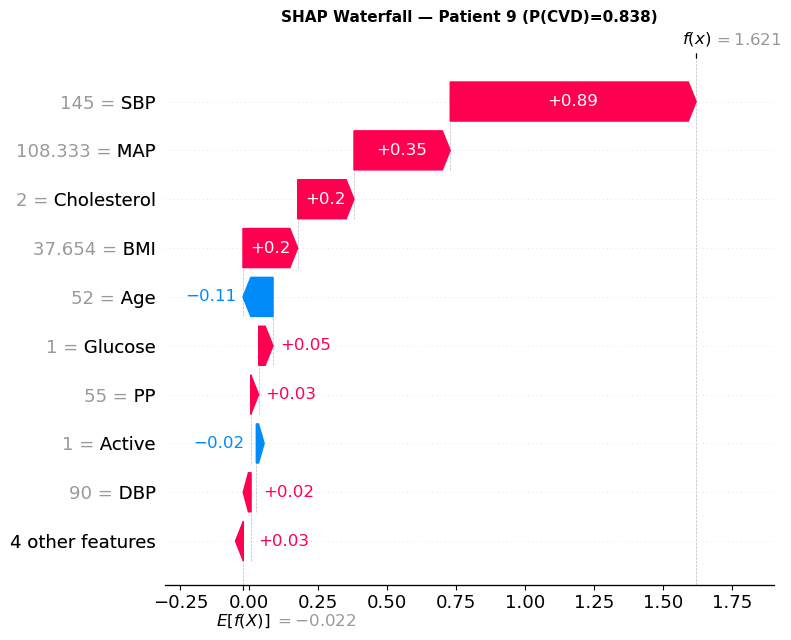

Saved: shap_waterfall_individual.png


In [23]:
# ── SHAP Waterfall plot ───────────────────────────────────────
shap_explanation = explainer(X_test_df)

plt.figure(figsize=(9, 6))
shap.plots.waterfall(shap_explanation[patient_idx], show=False)
plt.title(f'SHAP Waterfall — Patient {patient_idx} (P(CVD)={stack_proba[patient_idx]:.3f})',
          fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_waterfall_individual.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_waterfall_individual.png')

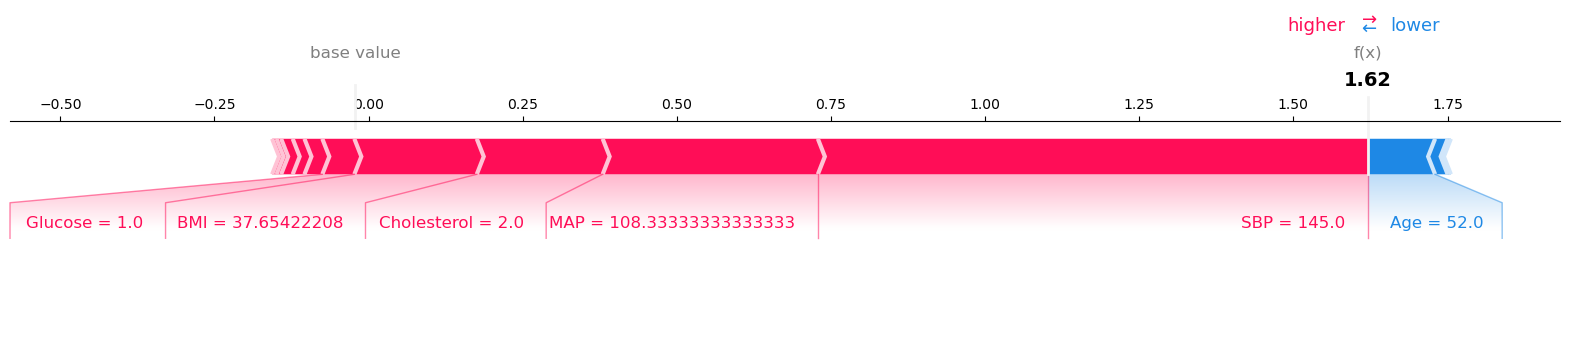

Saved: shap_force_individual.png


In [24]:
# ── SHAP Force plot ───────────────────────────────────────────
shap.initjs()
force_plot = shap.force_plot(
    explainer.expected_value,
    shap_values[patient_idx],
    X_test_df.iloc[patient_idx],
    matplotlib=True, show=False
)
plt.savefig('shap_force_individual.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: shap_force_individual.png')

## 12. Confusion Matrix

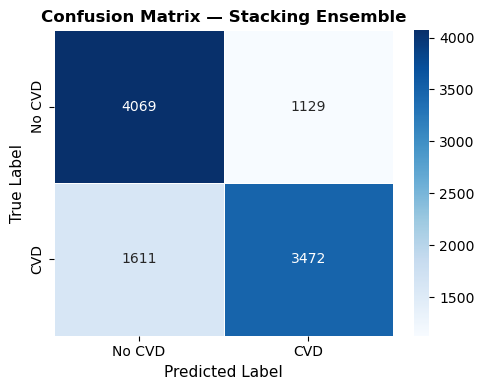

Saved: confusion_matrix_stacking.png

TP=3472  FP=1129  TN=4069  FN=1611
Sensitivity (Recall) = 0.6831
Specificity          = 0.7828


In [25]:
# ── Confusion matrix for Stacking Ensemble ────────────────────
cm = confusion_matrix(y_test, stack_pred)

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No CVD','CVD'], yticklabels=['No CVD','CVD'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Predicted Label', fontsize=11)
ax.set_ylabel('True Label', fontsize=11)
ax.set_title('Confusion Matrix — Stacking Ensemble', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix_stacking.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: confusion_matrix_stacking.png')

tn, fp, fn, tp = cm.ravel()
print(f'\nTP={tp}  FP={fp}  TN={tn}  FN={fn}')
print(f'Sensitivity (Recall) = {tp/(tp+fn):.4f}')
print(f'Specificity          = {tn/(tn+fp):.4f}')

## 13. ROC Curves — All Models

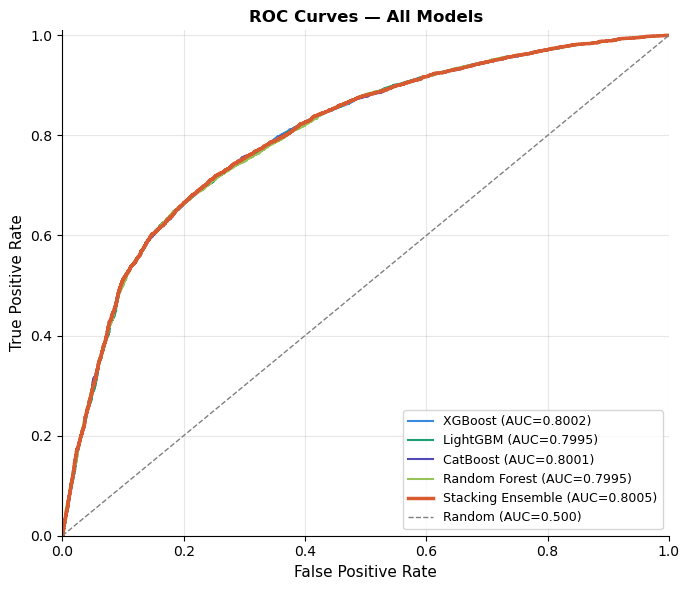

Saved: roc_curves_all_models.png


In [26]:
# ── ROC Curve for all models ──────────────────────────────────
all_probas = {
    'XGBoost'          : xgb_test_proba,
    'LightGBM'         : lgb_test_proba,
    'CatBoost'         : cat_test_proba,
    'Random Forest'    : rf_test_proba,
    'Stacking Ensemble': stack_proba,
}
palette = ['#378ADD', '#1D9E75', '#534AB7', '#97C459', '#D85A30']

fig, ax = plt.subplots(figsize=(7, 6))
for (name, proba), color in zip(all_probas.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val     = roc_auc_score(y_test, proba)
    lw = 2.5 if name == 'Stacking Ensemble' else 1.5
    ax.plot(fpr, tpr, color=color, lw=lw, label=f'{name} (AUC={auc_val:.4f})')

ax.plot([0,1],[0,1],'--', color='gray', lw=1, label='Random (AUC=0.500)')
ax.set_xlabel('False Positive Rate', fontsize=11)
ax.set_ylabel('True Positive Rate', fontsize=11)
ax.set_title('ROC Curves — All Models', fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='lower right')
ax.set_xlim([0,1]); ax.set_ylim([0,1.01])
ax.grid(alpha=0.3)
ax.spines[['top','right']].set_visible(False)
plt.tight_layout()
plt.savefig('roc_curves_all_models.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: roc_curves_all_models.png')

## 14. Final Summary Table

In [27]:
# ── Print final summary ───────────────────────────────────────
print('=' * 70)
print('   FINAL RESULTS — ALL MODELS (Test Set)')
print('=' * 70)
print(f'{"Model":<22} {"AUC":>7} {"Accuracy":>9} {"F1":>8} {"Precision":>11} {"Recall":>8}')
print('-' * 70)
for model, m in results_df.iterrows():
    marker = ' <-- BEST' if model == results_df.index[0] else ''
    print(f'{model:<22} {m["AUC"]:>7.4f} {m["Accuracy"]:>9.4f} '
          f'{m["F1"]:>8.4f} {m["Precision"]:>11.4f} {m["Recall"]:>8.4f}{marker}')
print('=' * 70)

print('\nSHAP Feature Ranking (XGBoost):')
print(f'{"Rank":<5} {"Feature":<14} {"Mean |SHAP|":>12}')
print('-' * 33)
for rank, (name, val) in enumerate(shap_rank, 1):
    print(f'{rank:<5} {name:<14} {val:>12.4f}')

print('\nOutput files saved:')
saved = ['model_comparison.png', 'shap_bar_plot.png', 'shap_beeswarm.png',
         'shap_dependence.png', 'shap_waterfall_individual.png',
         'shap_force_individual.png', 'confusion_matrix_stacking.png',
         'roc_curves_all_models.png']
for f in saved:
    print(f'  {f}')

   FINAL RESULTS — ALL MODELS (Test Set)
Model                      AUC  Accuracy       F1   Precision   Recall
----------------------------------------------------------------------
Stacking Ensemble       0.8005    0.7335   0.7171      0.7546   0.6831 <-- BEST
XGBoost                 0.8002    0.7329   0.7179      0.7512   0.6874
CatBoost                0.8001    0.7329   0.7164      0.7540   0.6825
Random Forest           0.7995    0.7322   0.7112      0.7618   0.6669
LightGBM                0.7995    0.7338   0.7174      0.7549   0.6835
MLP (baseline)          0.7970    0.7330   0.7180      0.7500   0.6760

SHAP Feature Ranking (XGBoost):
Rank  Feature         Mean |SHAP|
---------------------------------
1     SBP                  0.6501
2     Age                  0.2779
3     MAP                  0.2141
4     Cholesterol          0.2095
5     BMI                  0.1196
6     Active               0.0553
7     PP                   0.0451
8     Glucose              0.0449
9     DBP

In [29]:
# Run this to see all variables currently in memory
import numpy as np

# Print all variables that look like probability/prediction arrays
for name, val in sorted(globals().items()):
    if isinstance(val, np.ndarray) and val.ndim == 1 and len(val) > 1000:
        print(f"  {name:<30}  shape={val.shape}  dtype={val.dtype}  sample={val[:3]}")

  _                               shape=(3950,)  dtype=float64  sample=[       inf 0.88208022 0.88203075]
  cat_test_pred                   shape=(10281,)  dtype=int64  sample=[0 0 0]
  cat_test_proba                  shape=(10281,)  dtype=float64  sample=[0.08100332 0.37125363 0.26502283]
  fpr                             shape=(3950,)  dtype=float64  sample=[0. 0. 0.]
  high_risk_idx                   shape=(2729,)  dtype=int64  sample=[ 9 10 11]
  lgb_test_pred                   shape=(10281,)  dtype=int64  sample=[0 0 0]
  lgb_test_proba                  shape=(10281,)  dtype=float64  sample=[0.06503601 0.35940997 0.26893231]
  oof_cat                         shape=(47971,)  dtype=float64  sample=[0.2846063  0.25226356 0.81221942]
  oof_lgb                         shape=(47971,)  dtype=float64  sample=[0.25639127 0.26053423 0.83740436]
  oof_rf                          shape=(47971,)  dtype=float64  sample=[0.29320883 0.26201698 0.8057505 ]
  oof_xgb                         shape=(

In [30]:
# ── Save stacking + boosting predictions ─────────────────────────────
import numpy as np

np.save('proba_xgb.npy',   xgb_test_proba)
np.save('pred_xgb.npy',    xgb_test_pred)
np.save('proba_lgbm.npy',  lgb_test_proba)
np.save('pred_lgbm.npy',   lgb_test_pred)
np.save('proba_cat.npy',   cat_test_proba)
np.save('pred_cat.npy',    cat_test_pred)
np.save('proba_rf.npy',    rf_test_proba)
np.save('pred_rf.npy',     rf_test_pred)
np.save('proba_stack.npy', stack_proba)
np.save('pred_stack.npy',  stack_pred)

# Confirm
saved = {
    'proba_xgb'  : xgb_test_proba,
    'pred_xgb'   : xgb_test_pred,
    'proba_lgbm' : lgb_test_proba,
    'pred_lgbm'  : lgb_test_pred,
    'proba_cat'  : cat_test_proba,
    'pred_cat'   : cat_test_pred,
    'proba_rf'   : rf_test_proba,
    'pred_rf'    : rf_test_pred,
    'proba_stack': stack_proba,
    'pred_stack' : stack_pred,
}

for name, arr in saved.items():
    print(f"  ✓  {name+'.npy':<22}  shape={arr.shape}  dtype={arr.dtype}")

  ✓  proba_xgb.npy           shape=(10281,)  dtype=float32
  ✓  pred_xgb.npy            shape=(10281,)  dtype=int64
  ✓  proba_lgbm.npy          shape=(10281,)  dtype=float64
  ✓  pred_lgbm.npy           shape=(10281,)  dtype=int64
  ✓  proba_cat.npy           shape=(10281,)  dtype=float64
  ✓  pred_cat.npy            shape=(10281,)  dtype=int64
  ✓  proba_rf.npy            shape=(10281,)  dtype=float64
  ✓  pred_rf.npy             shape=(10281,)  dtype=int64
  ✓  proba_stack.npy         shape=(10281,)  dtype=float64
  ✓  pred_stack.npy          shape=(10281,)  dtype=int64
